# WebCortex: 2.5.3 vs 2.6.0, as a user would run it

This notebook runs WebCortex the way people use it. It builds apps and serves them. It
calls them as a browser, a `curl` user, an MCP client such as Claude Code, an agent with a
model behind it, and a camera on a WebSocket. It puts the **published 2.5.3 wheel** next to
the **development build** on every scenario.

* **Everyday scenarios:** a bookstore CRUD app, typed handlers, OpenAPI, an MCP session,
  agents with tools, handoffs, behaviours and flows, a camera stream, and the CLI on a
  fresh starter. Both builds should behave the same on these.
* **Edge cases:** each one is a bug fixed in 2.6.0, written the way someone would actually
  run into it. The expected value is what a correct framework does.
* **Isolation:** each scenario runs in its own interpreter against real servers on
  ephemeral ports, so a crash or hang in one cannot affect the next.
* **No real model API is called.** Agents run against WebCortex's offline fake provider,
  or a stub OpenAI-compatible server started inside the scenario.

**To run it:** use the kernel from `~/web_cortex_framework/.venv`, after
`maturin develop --release`. The first run installs the 2.5.3 wheel into
`~/.cache/webcortex-baseline/2.5.3`.

In [1]:
import json, os, sys, time
sys.path.insert(0, os.path.abspath("."))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import cases

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)
BUILDS = {"2.5.3": cases.baseline_path("2.5.3"), "2.6.0 (dev)": cases.dev_path()}
for label, path in BUILDS.items():
    print(f"{label:12} {path}")
everyday = [c for c in cases.CASES if c.everyday]
edge = [c for c in cases.CASES if not c.everyday]
print(f"{len(cases.CASES)} scenarios: {len(everyday)} everyday, {len(edge)} edge cases, "
      f"in {len({c.section for c in cases.CASES})} areas")

2.5.3        ~/.cache/webcortex-baseline/2.5.3
2.6.0 (dev)  ~/web_cortex_framework/python
41 scenarios: 11 everyday, 30 edge cases, in 8 areas


## 1. Every scenario on both builds

`✅` means the app behaved correctly. `❌` lists the observations that were wrong,
with the correct value in brackets.

In [2]:
started = time.perf_counter()
outcomes = {label: [cases.run_case(c, path) for c in cases.CASES] for label, path in BUILDS.items()}
verdicts = {label: [cases.judge(c, o) for c, o in zip(cases.CASES, outs)] for label, outs in outcomes.items()}
print(f"ran {sum(len(v) for v in outcomes.values())} scenario processes in {time.perf_counter() - started:.0f}s")


def cell(v):
    return "✅" if v["ok"] else "❌ " + (v["why"][:110] + ("…" if len(v["why"]) > 110 else ""))


rows = []
for i, c in enumerate(cases.CASES):
    row = {"area": c.section, "scenario": c.label, "kind": "everyday" if c.everyday else "edge"}
    for label in BUILDS:
        row[label] = cell(verdicts[label][i])
    rows.append(row)
table = pd.DataFrame(rows)
display(table.style.set_properties(**{"text-align": "left"}).hide(axis="index"))

ran 82 scenario processes in 61s


area,scenario,kind,2.5.3,2.6.0 (dev)
REST,bookstore CRUD round trip,everyday,✅,✅
REST,"Python handlers: typed params, errors, defaults",everyday,✅,✅
REST,OpenAPI lists every route,everyday,✅,✅
MCP,"Claude Code style session: initialize, list, call",everyday,✅,✅
Agents,agent calls a tool through the fake provider,everyday,✅,✅
Agents,handoff from front desk to specialist,everyday,✅,✅
Agents,behaviour fans out calls and returns usage,everyday,✅,✅
Agents,pipeline flow runs both steps,everyday,✅,✅
Agents,"provider failure is a coded error, server stays up",everyday,✅,✅
Devices,"camera pushes frames over WebSocket, snapshot serves the latest",everyday,✅,✅


## 2. Scoreboard by area

,2.5.3,2.6.0 (dev)
area,,
Agents,5 / 9,9 / 9
CLI,1 / 2,2 / 2
Devices,1 / 6,6 / 6
HTTP,0 / 9,9 / 9
MCP,1 / 2,2 / 2
Python,0 / 9,9 / 9
REST,3 / 3,3 / 3
Safety,0 / 1,1 / 1


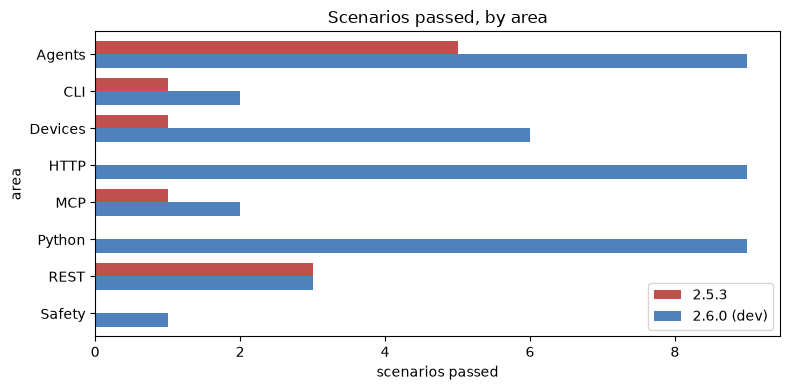

2.5.3        passes 11 / 41
2.6.0 (dev)  passes 41 / 41


In [3]:
score = (table.assign(**{label: [v["ok"] for v in verdicts[label]] for label in BUILDS})
         .groupby("area")[list(BUILDS)].agg(["sum", "count"]))
summary = pd.DataFrame({label: score[label]["sum"].astype(str) + " / " + score[label]["count"].astype(str)
                        for label in BUILDS})
display(summary)

passed = pd.DataFrame({label: score[label]["sum"] for label in BUILDS})
ax = passed.plot.barh(figsize=(8, 4), color=["#c0504d", "#4f81bd"], width=0.75)
ax.set_xlabel("scenarios passed")
ax.set_title("Scenarios passed, by area")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

for label in BUILDS:
    ok = sum(v["ok"] for v in verdicts[label])
    print(f"{label:12} passes {ok:2} / {len(cases.CASES)}")

## 3. Everyday use: does anything regress?

These scenarios are ordinary use, and both builds should produce the same observations.
The table shows every observation, not only the ones the scenario checks, along with
any difference between the builds.

In [4]:
diffs = []
for i, c in enumerate(cases.CASES):
    if not c.everyday:
        continue
    a, b = (outcomes[label][i].get("value") for label in BUILDS)
    if a is None or b is None:
        diffs.append({"scenario": c.label, "observation": "(run failed)", "2.5.3": a, "2.6.0": b})
        continue
    for key in sorted(set(a) | set(b)):
        if a.get(key) != b.get(key):
            diffs.append({"scenario": c.label, "observation": key, "2.5.3": a.get(key), "2.6.0": b.get(key)})
if diffs:
    display(pd.DataFrame(diffs))
else:
    display(Markdown(f"**No differences.** All {len(everyday)} everyday scenarios produced identical "
                     "observations on both builds."))

**No differences.** All 11 everyday scenarios produced identical observations on both builds.

## 4. What 2.5.3 did, case by case

For each edge case: what 2.5.3 actually observed, next to what 2.6.0 observed.

In [5]:
for i, c in enumerate(cases.CASES):
    if c.everyday:
        continue
    old, new = (outcomes[label][i] for label in BUILDS)
    display(Markdown(f"**{c.section} — {c.label}.** {c.why}"))
    keys = list(c.expect)
    frame = pd.DataFrame({
        "observation": keys,
        "correct": [json.dumps(c.expect[k], default=str) for k in keys],
        "2.5.3": [json.dumps(old.get("value", {}).get(k, old.get("error")), default=str)[:80] for k in keys],
        "2.6.0": [json.dumps(new.get("value", {}).get(k, new.get("error")), default=str)[:80] for k in keys],
    })
    display(frame.style.hide(axis="index"))

**HTTP — HEAD on a GET route (curl -I, load balancer checks).** 2.5.3 answered 405 to HEAD on every route, so `curl -I` and LB health checks failed.

observation,correct,2.5.3,2.6.0
get,200,200,200
head,200,405,200
head_body_empty,true,true,true
length_matches,true,false,true


**HTTP — SIGTERM lets an in-flight slow request finish.** 2.5.3's drain never waited (a u32 permit truncation), so a request in flight at SIGTERM was cut off.

observation,correct,2.5.3,2.6.0
status,200,"""RemoteDisconnected('Remote end closed connection without response')""",200
body,"{""finished"": true}",null,"{""finished"": true}"
exit_code,0,0,0


**HTTP — static_files serves its index at the mount point.** 2.5.3 answered 404 at /assets/ and /assets because the catch-all never matched an empty rest.

...

observation,correct,2.5.3,2.6.0
upgrade,101,101,101
ready_first,true,true,true
close_code,1002,null,1002


**Devices — Image(b'junk', 'image/png') is refused.** 2.5.3 trusted the media-type label, so junk bytes labelled image/png were sent to the model as an image.

observation,correct,2.5.3,2.6.0
junk_refused,true,false,true
mislabelled_jpeg_refused,true,false,true
real_png_ok,"""image/png""","""image/png""","""image/png"""


**Devices — concurrent snapshots of a pulled IP camera share one fetch.** 2.5.3 fetched the IP camera once per asker: ten snapshots meant ten connections to one slow camera.

observation,correct,2.5.3,2.6.0
statuses,"[200, 200, 200, 200, 200, 200, 200, 200, 200, 200]","[200, 200, 200, 200, 200, 200, 200, 200, 200, 200]","[200, 200, 200, 200, 200, 200, 200, 200, 200, 200]"
shared,true,false,true


## 5. Throughput

The same app runs on each build: a Rust-executed static route, a Rust SQL route from
`app.resource`, and a Python handler. Eight keep-alive clients hit each one. The rounds
alternate between builds and the best of three is kept, because machine load moves these
numbers by about ±20%. The clients are Python, so they cap the rate at about the same
level on both builds. This is a regression check, not a peak benchmark; `ab` or `oha`
measure the peak.

,2.5.3,2.6.0 (dev),2.6.0 / 2.5.3
/ping (Rust static),25148,25500,1.01
/items (Rust SQL),25510,25164,0.99
/py (Python handler),23181,22848,0.99


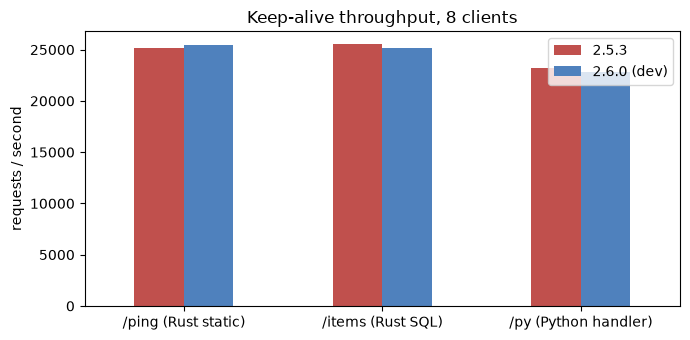

In [6]:
timing_case = cases.Case("timing", "throughput", cases.TIMING, {})
rates = {label: {} for label in BUILDS}
for _ in range(2):
    for label, path in BUILDS.items():
        out = cases.run_case(timing_case, path)
        for route, rps in out["value"].items():
            rates[label][route] = max(rates[label].get(route, 0), rps)
speed = pd.DataFrame(rates).round(0).astype(int)
speed["2.6.0 / 2.5.3"] = (speed["2.6.0 (dev)"] / speed["2.5.3"]).round(2)
speed.index = ["/ping (Rust static)", "/items (Rust SQL)", "/py (Python handler)"]
display(speed)
ax = speed[list(BUILDS)].plot.bar(figsize=(7, 3.5), color=["#c0504d", "#4f81bd"], rot=0)
ax.set_ylabel("requests / second")
ax.set_title("Keep-alive throughput, 8 clients")
plt.tight_layout()
plt.show()

## 6. Verdict

In [7]:
old_fails = sum(not v["ok"] for v in verdicts["2.5.3"])
new_fails = sum(not v["ok"] for v in verdicts["2.6.0 (dev)"])
regressions = [c.label for i, c in enumerate(cases.CASES)
               if verdicts["2.5.3"][i]["ok"] and not verdicts["2.6.0 (dev)"][i]["ok"]]
slowest = speed["2.6.0 / 2.5.3"].min()
print(f"scenarios: {len(cases.CASES)} | 2.5.3 fails {old_fails} | 2.6.0 fails {new_fails} | "
      f"regressions {len(regressions)} | everyday differences {len(diffs)} | "
      f"slowest route vs 2.5.3: {slowest:.2f}x")
assert new_fails == 0, [c.label for i, c in enumerate(cases.CASES) if not verdicts["2.6.0 (dev)"][i]["ok"]]
assert not regressions, regressions
assert not diffs, diffs
assert slowest > 0.8, speed

scenarios: 41 | 2.5.3 fails 30 | 2.6.0 fails 0 | regressions 0 | everyday differences 0 | slowest route vs 2.5.3: 0.99x
